In [3]:
!pip install transformers datasets torch scikit-learn accelerate

In [6]:
import pandas as pd

df = pd.read_csv("/content/go_emotions_dataset.csv")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nColumns:")
print(df.columns)

        id                                               text  \
0  eew5j0j                                    That game hurt.   
1  eemcysk   >sexuality shouldn’t be a grouping category I...   
2  ed2mah1     You do right, if you don't care then fuck 'em!   
3  eeibobj                                 Man I love reddit.   
4  eda6yn6  [NAME] was nowhere near them, he was by the Fa...   

   example_very_unclear  admiration  amusement  anger  annoyance  approval  \
0                 False           0          0      0          0         0   
1                  True           0          0      0          0         0   
2                 False           0          0      0          0         0   
3                 False           0          0      0          0         0   
4                 False           0          0      0          0         0   

   caring  confusion  ...  love  nervousness  optimism  pride  realization  \
0       0          0  ...     0            0         0      0 

In [7]:
# 1. Missing values per column
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# 2. Duplicate checks
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df['id'].duplicated().sum())
print("Duplicate texts:", df['text'].duplicated().sum())

# 3. Data types
print("\nData types:")
print(df.dtypes.value_counts())

# 4. Empty or very short texts
print("\nEmpty texts:", (df['text'].str.strip() == '').sum())

Missing values per column:
id                      0
text                    0
example_very_unclear    0
admiration              0
amusement               0
anger                   0
annoyance               0
approval                0
caring                  0
confusion               0
curiosity               0
desire                  0
disappointment          0
disapproval             0
disgust                 0
embarrassment           0
excitement              0
fear                    0
gratitude               0
grief                   0
joy                     0
love                    0
nervousness             0
optimism                0
pride                   0
realization             0
relief                  0
remorse                 0
sadness                 0
surprise                0
neutral                 0
dtype: int64

Total missing values: 0

Duplicate rows: 56737
Duplicate ids: 153214
Duplicate texts: 153493

Data types:
int64     28
object     2
bool       1
Name: co

Emotion counts (all rows):
neutral           55298
approval          17620
admiration        17131
annoyance         13618
gratitude         11625
disapproval       11424
curiosity          9692
amusement          9245
realization        8785
optimism           8715
disappointment     8469
love               8191
anger              8084
joy                7983
confusion          7359
sadness            6758
caring             5999
excitement         5629
surprise           5514
disgust            5301
desire             3817
fear               3197
remorse            2525
embarrassment      2476
nervousness        1810
pride              1302
relief             1289
grief               673
dtype: int64

Target emotion counts:
joy         7983
sadness     6758
love        8191
anger       8084
fear        3197
surprise    5514
dtype: int64

Labels per row:
0       3411
1     171820
2      31187
3       4218
4        399
5        106
6         53
7         20
8          6
9          3
10

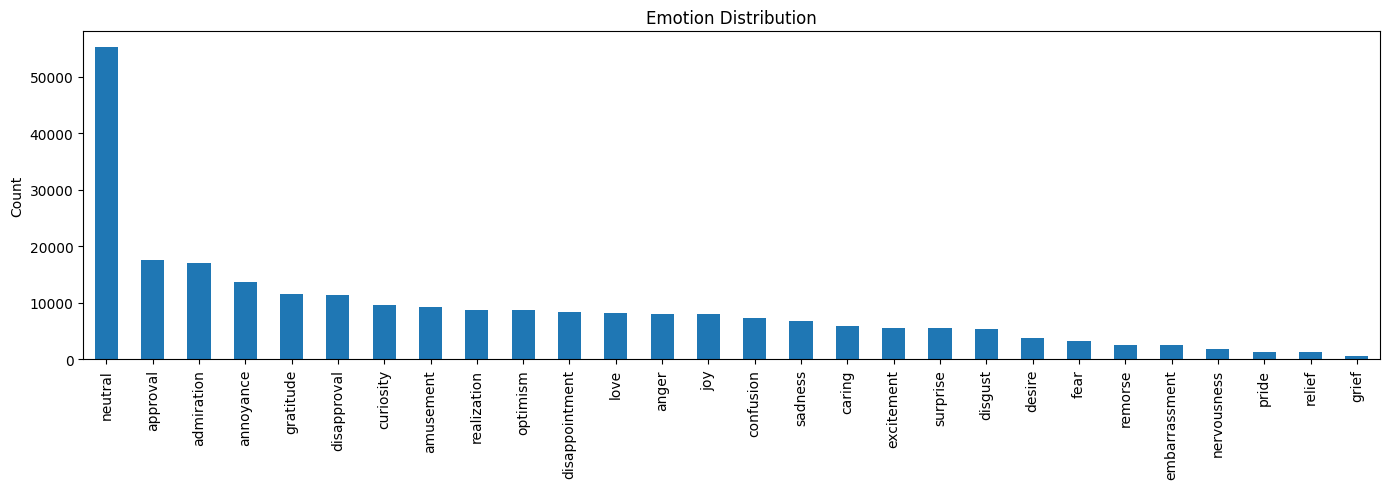

In [8]:
# All emotion columns (everything except id, text, example_very_unclear)
emotion_cols = [c for c in df.columns if c not in ['id', 'text', 'example_very_unclear']]

# 1. Count of rows labeled with each emotion
emotion_counts = df[emotion_cols].sum().sort_values(ascending=False)
print("Emotion counts (all rows):")
print(emotion_counts)

# 2. Focus on your six target emotions
target = ['joy', 'sadness', 'love', 'anger', 'fear', 'surprise']
print("\nTarget emotion counts:")
print(df[target].sum())

# 3. How many labels does each row have?
print("\nLabels per row:")
print(df[emotion_cols].sum(axis=1).value_counts().sort_index())

# 4. Unclear examples
print("\nVery unclear examples:", df['example_very_unclear'].sum())

# 5. Bar chart
import matplotlib.pyplot as plt
emotion_counts.plot(kind='bar', figsize=(14, 5), title='Emotion Distribution')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [9]:
target = ['joy', 'sadness', 'love', 'anger', 'fear', 'surprise']
other_cols = [c for c in emotion_cols if c not in target]

# 1. Remove unclear examples
d = df[df['example_very_unclear'] == False]

# 2. Keep rows with exactly one target emotion and no other emotion
mask = (d[target].sum(axis=1) == 1) & (d[other_cols].sum(axis=1) == 0)
sub = d[mask].copy()

# 3. Create a single text label column
sub['label'] = sub[target].idxmax(axis=1)

# 4. Remove comments where raters gave conflicting target labels
n_labels = sub.groupby('id')['label'].nunique()
conflict_ids = n_labels[n_labels > 1].index
sub = sub[~sub['id'].isin(conflict_ids)]

# 5. One row per comment
sub = sub.drop_duplicates(subset='id')

# Keep only what we need
sub = sub[['id', 'text', 'label']].reset_index(drop=True)

print("Conflicting comments removed:", len(conflict_ids))
print("Final shape:", sub.shape)
print("\nClass counts:")
print(sub['label'].value_counts())
print("\nClass percentages:")
print((sub['label'].value_counts(normalize=True) * 100).round(1))

print("\nSample rows:")
print(sub.sample(8, random_state=42))

Conflicting comments removed: 1296
Final shape: (14604, 3)

Class counts:
label
anger       3516
joy         2805
love        2531
sadness     2498
surprise    2208
fear        1046
Name: count, dtype: int64

Class percentages:
label
anger       24.1
joy         19.2
love        17.3
sadness     17.1
surprise    15.1
fear         7.2
Name: proportion, dtype: float64

Sample rows:
            id                                               text     label
169    eehyntr                                  Wow, now I am sad   sadness
2054   eebcfza  “Attack on masculinity” I’m dying over here yo...     anger
10437  ef13ceg  All the [NAME] who’ve been harassed or assault...       joy
9457   edrl99e  Breaking news- Man having fun at party is mock...       joy
14476  ee6hq6q             Looks like you don't have a story too.   sadness
4202   edc9a8b       Everyday, always, I am a hero inside my head      love
13303  eekvjns  Given I had zero interaction I couldn't even b...  surprise
13702  ee

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Label <-> id mappings
labels = sorted(sub['label'].unique())
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
sub['label_id'] = sub['label'].map(label2id)
print("label2id:", label2id)

# 2. Stratified split: 80% train, 10% validation, 10% test
train_df, temp_df = train_test_split(
    sub, test_size=0.20, stratify=sub['label_id'], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label_id'], random_state=42)

print("\nSizes -> train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

# 3. Check class proportions are preserved
print("\nClass % per split:")
print(pd.DataFrame({
    'train': train_df['label'].value_counts(normalize=True),
    'val':   val_df['label'].value_counts(normalize=True),
    'test':  test_df['label'].value_counts(normalize=True),
}).mul(100).round(1))

# 4. Class weights (computed from the training set only)
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(labels)),
    y=train_df['label_id'])
print("\nClass weights:")
for l, w in zip(labels, weights):
    print(f"  {l}: {w:.2f}")

# 5. Make sure no comment appears in more than one split
print("\nOverlap train/test:", len(set(train_df['id']) & set(test_df['id'])))
print("Overlap train/val:", len(set(train_df['id']) & set(val_df['id'])))

label2id: {'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'sadness': 4, 'surprise': 5}

Sizes -> train: 11683 | val: 1460 | test: 1461

Class % per split:
          train   val  test
label                      
anger      24.1  24.0  24.1
joy        19.2  19.2  19.2
love       17.3  17.3  17.3
sadness    17.1  17.1  17.1
surprise   15.1  15.1  15.1
fear        7.2   7.2   7.1

Class weights:
  anger: 0.69
  fear: 2.33
  joy: 0.87
  love: 0.96
  sadness: 0.97
  surprise: 1.10

Overlap train/test: 0
Overlap train/val: 0


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Word count stats:
count    11683.000000
mean        12.484978
std          6.639313
min          1.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         31.000000
Name: text, dtype: float64

Token count stats:
count    11683.000000
mean        18.801592
std          8.567386
min          3.000000
25%         12.000000
50%         18.000000
75%         25.000000
max         82.000000
Name: text, dtype: float64
90th percentile: 31 tokens
95th percentile: 33 tokens
99th percentile: 38 tokens
99.5th percentile: 39 tokens
max_length=32: 6.75% of texts truncated
max_length=48: 0.03% of texts truncated
max_length=64: 0.01% of texts truncated
max_length=128: 0.00% of texts truncated

Example text: Same for me, feels like i've been made alone just so my brother can get all the attention
Tokens: ['same', 'for', 'me', ',', 'feels', 'like', 'i', "'", 've', 'been', 'made', 'alone', 'just', 'so', 'my', 'brother', 'can', 'get', 'all', 'the', 'attention']


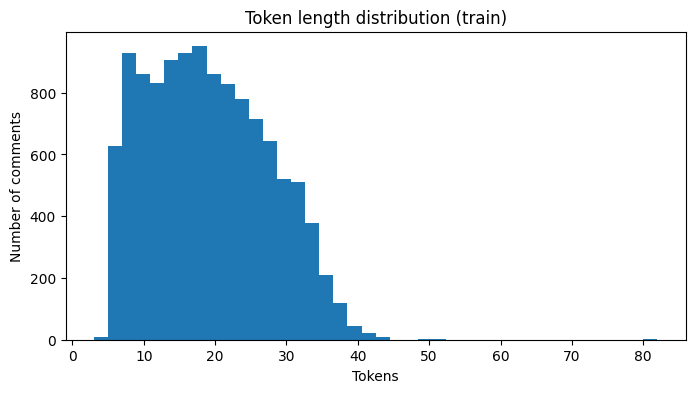

In [11]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 1. Word counts (quick view)
word_lens = train_df['text'].str.split().str.len()
print("Word count stats:")
print(word_lens.describe())

# 2. Token counts (what DistilBERT actually sees)
token_lens = train_df['text'].apply(lambda t: len(tokenizer.encode(t, truncation=False)))
print("\nToken count stats:")
print(token_lens.describe())

# 3. Percentiles to choose max_length
for p in [90, 95, 99, 99.5]:
    print(f"{p}th percentile: {int(np.percentile(token_lens, p))} tokens")

# 4. How much would be cut off at different max_length values?
for m in [32, 48, 64, 128]:
    pct = (token_lens > m).mean() * 100
    print(f"max_length={m}: {pct:.2f}% of texts truncated")

# 5. Example of tokenization
example = train_df['text'].iloc[0]
print("\nExample text:", example)
print("Tokens:", tokenizer.tokenize(example))

# 6. Histogram
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.hist(token_lens, bins=40)
plt.title("Token length distribution (train)")
plt.xlabel("Tokens")
plt.ylabel("Number of comments")
plt.show()

In [12]:
from datasets import Dataset, DatasetDict
from transformers import DataCollatorWithPadding

MAX_LEN = 48

# 1. Convert pandas DataFrames to HF Datasets (keep text + numeric label only)
def to_hf(df_):
    d = df_[['text', 'label_id']].rename(columns={'label_id': 'labels'}).reset_index(drop=True)
    return Dataset.from_pandas(d)

raw_ds = DatasetDict({
    'train': to_hf(train_df),
    'validation': to_hf(val_df),
    'test': to_hf(test_df),
})

# 2. Tokenize (no padding here; the collator pads per batch)
def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LEN)

tokenized_ds = raw_ds.map(tokenize_fn, batched=True, remove_columns=['text'])

# 3. Data collator for dynamic padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 4. Inspect the result
print(tokenized_ds)
print("\nColumns:", tokenized_ds['train'].column_names)
sample = tokenized_ds['train'][0]
print("\nSample input_ids:", sample['input_ids'])
print("Sample label:", sample['labels'], "->", id2label[sample['labels']])
print("Decoded:", tokenizer.decode(sample['input_ids']))

# 5. Test the collator on a small batch
batch = data_collator([tokenized_ds['train'][i] for i in range(4)])
print("\nBatch shapes:")
for k, v in batch.items():
    print(f"  {k}: {tuple(v.shape)}")

Map:   0%|          | 0/11683 [00:00<?, ? examples/s]

Map:   0%|          | 0/1460 [00:00<?, ? examples/s]

Map:   0%|          | 0/1461 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 11683
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1460
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1461
    })
})

Columns: ['labels', 'input_ids', 'token_type_ids', 'attention_mask']

Sample input_ids: [101, 2168, 2005, 2033, 1010, 5683, 2066, 1045, 1005, 2310, 2042, 2081, 2894, 2074, 2061, 2026, 2567, 2064, 2131, 2035, 1996, 3086, 102]
Sample label: 4 -> sadness
Decoded: [CLS] same for me, feels like i ' ve been made alone just so my brother can get all the attention [SEP]

Batch shapes:
  labels: (4,)
  input_ids: (4, 32)
  token_type_ids: (4, 32)
  attention_mask: (4, 32)


In [14]:
!pip install evaluate

In [15]:
import evaluate

print("Evaluate library installed successfully!")

Evaluate library installed successfully!


In [17]:
import torch
import torch.nn as nn
import evaluate

In [18]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, y = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro"),
    }

In [20]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

In [21]:
def compute_metrics(eval_pred):
    logits, y = eval_pred

    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(y, preds),
        "macro_f1": f1_score(
            y, preds, average="macro"
        )
    }

print("Evaluation metrics configured successfully!")

Evaluation metrics configured successfully!


In [22]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer initialized successfully!")

NameError: name 'model' is not defined